# Calculo dos tempos intermediários dos algoritmos de MDS

In [17]:
import csv
import gc
import sys
from fractions import Fraction
from pathlib import Path
from time import perf_counter_ns
from uuid import uuid4

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
for directory in (cwd, *cwd.parents):
    src = directory / "src"
    if (src / "complex_networks").is_dir():
        for import_path in (directory, src):
            if str(import_path) not in sys.path:
                sys.path.insert(0, str(import_path))
        break

from src.complex_networks.algorithms.mds.demds import mds_solver_demds
from src.complex_networks.algorithms.mds.iterated_greedy import mds_solver_iterated_greedy
from src.complex_networks.config import RAW_DATA_DIR, RESULTS_DIR
from src.complex_networks.io import load_edgelist, preprocess
from src.complex_networks.utils import iter_files

O prazo interno do DemDS usa segundos inteiros de CPU. O Iterated
Greedy verifica o tempo decorrido após cada rodada e também para
após 200 rodadas consecutivas sem melhora. Os dois recebem
`TIME_LIMIT_S` e as medições externas usam segundos decorridos desde
a chamada. Uma melhoria posterior a `TIME_LIMIT_S` conserva seu
instante real no histórico.

In [18]:
INSTANCE_NAME = "roadNet-CA"
SEEDS = (1,)
TIME_LIMIT_S = 600
IG_BETA = 0.2
RODAR_LOTE = False
ORDEM_ARQUIVOS = "size"
SALVAR_CSV = True

ALGORITMOS = {
    "DemDS": (mds_solver_demds, "cpu", {}),
    #"Iterated Greedy": (mds_solver_iterated_greedy, "decorrido", {"beta": IG_BETA}),
}

In [19]:
def medir_execucao(G, instancia, algoritmo, seed):
    solver, relogio_limite, parametros = ALGORITMOS[algoritmo]
    run_id = uuid4().hex
    eventos = []

    def registrar(cardinalidade):
        eventos.append((perf_counter_ns() - inicio_ns, cardinalidade))

    solucao = None
    erro = None
    inicio_ns = perf_counter_ns()
    try:
        solucao = solver(
            G,
            seed=seed,
            time_limit=TIME_LIMIT_S,
            on_improvement=registrar,
            **parametros,
        )
    except Exception as exc:
        fim_ns = perf_counter_ns()
        erro = f"{type(exc).__name__}: {exc}"
    else:
        fim_ns = perf_counter_ns()

    cardinalidade = len(solucao) if solucao is not None else None
    valida = (
        solucao is not None
        and all(v in G for v in solucao)
        and nx.is_dominating_set(G, solucao)
    )
    if erro is None and not valida:
        erro = "O conjunto retornado não domina o grafo."
    if erro is None and (not eventos or eventos[-1][1] != cardinalidade):
        erro = "A última cardinalidade registrada difere da solução retornada."

    resumo = {
        "run_id": run_id,
        "instancia": instancia,
        "algoritmo": algoritmo,
        "seed": seed,
        "n_nodes": G.number_of_nodes(),
        "n_edges": G.number_of_edges(),
        "limite_s": TIME_LIMIT_S,
        "relogio_limite": relogio_limite,
        "beta": parametros.get("beta"),
        "tempo_total_s": (fim_ns - inicio_ns) / 1_000_000_000,
        "cardinalidade_final": cardinalidade,
        "tempo_ate_melhor_s": eventos[-1][0] / 1_000_000_000 if erro is None else None,
        "n_eventos": len(eventos),
        "valida": valida,
        "status": "ok" if erro is None else "erro",
        "erro": erro,
    }
    historico = [
        {
            "run_id": run_id,
            "tempo_s": tempo_ns / 1_000_000_000,
            "cardinalidade": tamanho,
        }
        for tempo_ns, tamanho in eventos
    ]
    return resumo, historico


def salvar_linhas(path, linhas):
    if not linhas:
        return
    precisa_cabecalho = not path.exists()
    with path.open("a", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(linhas[0]))
        if precisa_cabecalho:
            writer.writeheader()
        writer.writerows(linhas)

In [20]:
if RODAR_LOTE:
    caminhos = list(iter_files(RAW_DATA_DIR, "*.txt.gz", order=ORDEM_ARQUIVOS))
else:
    caminhos = [RAW_DATA_DIR / f"{INSTANCE_NAME}.txt.gz"]

if not caminhos:
    raise FileNotFoundError(f"Nenhum arquivo .txt.gz em {RAW_DATA_DIR}.")
if not SEEDS:
    raise ValueError("Informe pelo menos uma semente.")

pasta_resultados = None
if SALVAR_CSV:
    pasta_resultados = (
        RESULTS_DIR / "benchmarks" / "mds" / "tempos_intermediarios" / uuid4().hex
    )
    pasta_resultados.mkdir(parents=True)

resumos = []
historicos_em_memoria = []
for caminho in caminhos:
    G = None
    try:
        G = preprocess(load_edgelist(caminho))
        instancia = caminho.name.removesuffix(".txt.gz")
        for seed in SEEDS:
            for algoritmo in ALGORITMOS:
                print(f"{instancia} | {algoritmo} | seed {seed}", flush=True)
                resumo, historico = medir_execucao(G, instancia, algoritmo, seed)
                if pasta_resultados is not None:
                    salvar_linhas(pasta_resultados / "mds_melhorias.csv", historico)
                    salvar_linhas(pasta_resultados / "mds_execucoes.csv", [resumo])
                else:
                    historicos_em_memoria.extend(historico)
                resumos.append(resumo)
    finally:
        del G
        gc.collect()

execucoes = pd.DataFrame(resumos)
if pasta_resultados is not None:
    caminho_melhorias = pasta_resultados / "mds_melhorias.csv"
    historico_completo = (
        pd.read_csv(caminho_melhorias, dtype={"run_id": str})
        if caminho_melhorias.is_file()
        else pd.DataFrame(columns=["run_id", "tempo_s", "cardinalidade"])
    )
    print(pasta_resultados)
else:
    historico_completo = pd.DataFrame(
        historicos_em_memoria, columns=["run_id", "tempo_s", "cardinalidade"]
    )
display(execucoes)

roadNet-CA | DemDS | seed 1
/home/fernando/complex-networks/results/benchmarks/mds/tempos_intermediarios/8da0a5cec42148fe9450f05bdce531e5


,run_id,instancia,algoritmo,seed,n_nodes,n_edges,limite_s,relogio_limite,beta,tempo_total_s,cardinalidade_final,tempo_ate_melhor_s,n_eventos,valida,status,erro
0,3ca408fd813a4016b7beaefcb8750bee,roadNet-CA,DemDS,1,1965206,2766607,600,cpu,None,611.273979,590068,608.584699,29979,True,ok,None


In [21]:
INSTANCIA_ANALISE = INSTANCE_NAME
SEED_ANALISE = SEEDS[0]
TEMPOS_CONSULTA_S = (1, 5, 10, 30, 60)
GAPS_PERCENTUAIS = (10, 5, 1, 0)
OTIMOS = {"amazon0302": 35_587, "p2p-Gnutella04": 2227, "p2p-Gnutella31": 12582, "amazon0302":35587, "soc-Slashdot0902":15305, "amazon0505":47309}

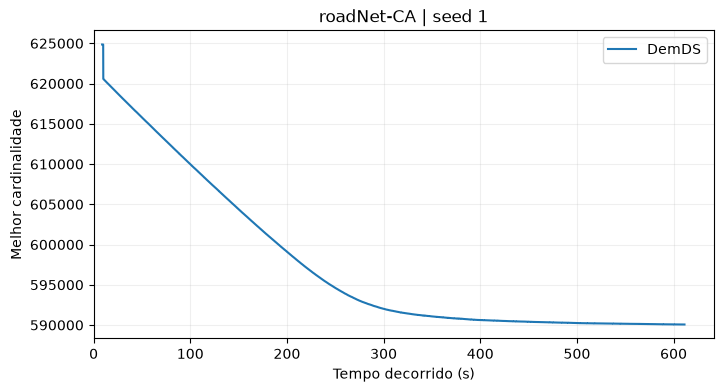

,algoritmo,tempo_s,melhor_cardinalidade
0,DemDS,1,NaN
1,DemDS,5,NaN
2,DemDS,10,620581.0
3,DemDS,30,618153.0
4,DemDS,60,614623.0


In [22]:
selecionadas = execucoes[
    (execucoes["instancia"] == INSTANCIA_ANALISE)
    & (execucoes["seed"] == SEED_ANALISE)
    & (execucoes["status"] == "ok")
]
qualidade_por_tempo = []
tempos_ate_alvo = []
otimo = OTIMOS.get(INSTANCIA_ANALISE)

if selecionadas.empty:
    print("Nenhuma execução válida para a instância e a semente escolhidas.")
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    for rodada in selecionadas.itertuples(index=False):
        eventos = historico_completo[
            historico_completo["run_id"] == rodada.run_id
        ].sort_values("tempo_s")
        ax.step(
            [*eventos["tempo_s"], rodada.tempo_total_s],
            [*eventos["cardinalidade"], rodada.cardinalidade_final],
            where="post",
            label=rodada.algoritmo,
        )
        for t in TEMPOS_CONSULTA_S:
            disponiveis = eventos.loc[eventos["tempo_s"] <= t, "cardinalidade"]
            qualidade_por_tempo.append({
                "algoritmo": rodada.algoritmo,
                "tempo_s": t,
                "melhor_cardinalidade": disponiveis.iloc[-1] if len(disponiveis) else None,
            })
        if otimo is not None and otimo > 0:
            for gap in GAPS_PERCENTUAIS:
                alvo = int(otimo * (1 + Fraction(str(gap)) / 100))
                atingimentos = eventos.loc[eventos["cardinalidade"] <= alvo, "tempo_s"]
                tempos_ate_alvo.append({
                    "algoritmo": rodada.algoritmo,
                    "gap_maximo_percentual": gap,
                    "cardinalidade_alvo": alvo,
                    "atingiu": not atingimentos.empty,
                    "tempo_ate_alvo_s": atingimentos.min() if len(atingimentos) else None,
                })
    if otimo is not None:
        ax.axhline(otimo, color="gray", linestyle="--", label="Ótimo")
    ax.set(xlabel="Tempo decorrido (s)", ylabel="Melhor cardinalidade", xlim=(0, None))
    ax.set_title(f"{INSTANCIA_ANALISE} | seed {SEED_ANALISE}")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()
    display(pd.DataFrame(qualidade_por_tempo))
    if tempos_ate_alvo:
        display(pd.DataFrame(tempos_ate_alvo))